In [1]:
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_TELEMETRY", "true")   # nada sale a internet salvo Databricks si se configura
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))   # los notebooks importan de src/, nunca al revés

import numpy as np
import pandas as pd
pd.set_option("display.width", 200, "display.max_columns", 40)

# 02 · EDA — qué son los datos y qué decisiones tomamos

Los datos personales se eliminan **al cargar** (`load_raw`): este notebook nunca muestra nombres, documentos,
direcciones ni teléfonos. Cada hallazgo termina en una decisión (tabla final y `reports/01_eda.md`).

In [2]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from proyecto.config import RAW_CSV, GROUP_COL, EXCLUDED_ON_PURPOSE
from proyecto.data.cleaning import load_raw, personal_columns

raw_columns = pd.read_csv(RAW_CSV, nrows=0).columns
print(f"columnas personales que se eliminan al cargar: {len(personal_columns(raw_columns))}")
df = load_raw()
df["mora_30"] = (df["DIAS DE MORA"] > 30).astype(int)
apertura = pd.to_datetime(df["FECHA APERTURA DEL PRESTAMO"].astype(str), format="%Y%m%d")
FIG = ROOT / "reports" / "figuras"; FIG.mkdir(parents=True, exist_ok=True)
print(df.shape, "· sin datos personales:", not personal_columns(df.columns))

columnas personales que se eliminan al cargar: 49


(60000, 143) · sin datos personales: True


## 1. Unidad de análisis y objetivo

In [3]:
por_cliente = df.groupby(GROUP_COL).size()
print("una fila = un crédito; créditos por cliente:", por_cliente.value_counts().sort_index().to_dict())
print(f"objetivo mora_30: {df['mora_30'].mean():.1%} en mora")
mixtos = df.groupby(GROUP_COL)["mora_30"].agg(["size", "mean"])
print("clientes con créditos en mora y al día a la vez:", int(((mixtos["mean"] > 0) & (mixtos["mean"] < 1)).sum()))

una fila = un crédito; créditos por cliente: {1: 29228, 2: 8385, 3: 2966, 4: 1276}
objetivo mora_30: 19.0% en mora
clientes con créditos en mora y al día a la vez: 4669


## 2. Calidad: columnas vacías, constantes y duplicados

In [4]:
vacias = [c for c in df.columns if df[c].isna().all()]
constantes = [c for c in df.columns if df[c].nunique(dropna=True) == 1]
print(f"100 % vacías: {len(vacias)} · un solo valor: {len(constantes)}")
print("duplicados exactos (sin el número del crédito):", int(df.drop(columns=["NUMERO DE LA COLOCACION"]).duplicated().sum()))
print("números del crédito repetidos:", int(df["NUMERO DE LA COLOCACION"].duplicated().sum()))
print("vacíos en el objetivo (DIAS DE MORA):", int(df["DIAS DE MORA"].isna().sum()), "· negativos:", int((df["DIAS DE MORA"] < 0).sum()))
print("CALIFICACION CARTERA vacía:", f"{df['CALIFICACION CARTERA'].isna().mean():.1%}")

100 % vacías: 9 · un solo valor: 54


duplicados exactos (sin el número del crédito): 0
números del crédito repetidos: 0
vacíos en el objetivo (DIAS DE MORA): 0 · negativos: 0
CALIFICACION CARTERA vacía: 3.6%


## 3. Fuga de información: ¿qué columnas ya contienen la respuesta?

AUC de cada columna numérica **por sí sola** frente a `mora_30` (0,5 = no dice nada; 1,0 = es la respuesta).

In [5]:
def auc_simple(s, y):
    v = pd.to_numeric(s, errors="coerce")
    if v.notna().mean() < 0.5 or v.nunique() < 2:
        return np.nan
    a = roc_auc_score(y, v.fillna(v.median()))
    return max(a, 1 - a)

fuga = pd.Series({c: auc_simple(df[c], df["mora_30"]) for c in df.columns if c not in ("mora_30", GROUP_COL)}).dropna()
fuga = fuga.sort_values(ascending=False)
fuga.round(3).to_csv(ROOT / "reports" / "02_auc_por_columna.csv", header=["auc"])
print(fuga.head(15).round(3).to_string())

DIAS DE MORA                    1.000
CAJA DE MORA A LA FECHA         1.000
NRO CUOTAS VENCIDAS             0.976
VLR CAPITAL PAGO MINIMO         0.968
VLR MINIMO DE PAGO              0.965
FEC CUOTA MAS ANTIG PEND PAG    0.915
ESTADO DEL PRESTAMO             0.912
VLR CARGOS PAGO MINIMO          0.877
FECHA EFEC ULTIMO PAGO          0.859
INT MORA EN PESOS 2             0.841
INT CORRIENTE PESOS 3           0.841
INT. MORA PAGO TOTAL            0.802
T.INT.MORA EN PESOS             0.802
VLR MORA PAGO MINIMO            0.802
INT MORA EN PESOS 1             0.794


Todas las columnas con AUC alto describen lo que pasó **después** de aprobar (días de mora, cuotas vencidas, intereses
de mora, saldos, pagos, estado y calificación). **Ninguna se puede usar**: el día de la aprobación no existen.

## 4. El bloque reestructurado (`CONDICION ESPECIAL = 1`)

In [6]:
bloque = df["CONDICION ESPECIAL"] == 1
cols = ["PLAZO UNIDAD TIEMPO PRODUCTO", "NUMERO DE PAGOS PACTADOS", "NRO TASA INT.MORA", "NRO DE UTILIZACINES DEL PLAN",
        "ESTADO AFILIACION DEL CANAL", "NRO CUOTAS PAGADAS"]
print(f"créditos en el bloque: {bloque.sum():,} · mora: {df.loc[bloque, 'mora_30'].mean():.0%}")
print(pd.DataFrame({"bloque (media)": df.loc[bloque, cols].mean(), "resto (media)": df.loc[~bloque, cols].mean()}).round(2))
print("plazo = 1 mes fuera del bloque:", int((df.loc[~bloque, "PLAZO UNIDAD TIEMPO PRODUCTO"] == 1).sum()))
print("EVENTO vacío fuera del bloque:", int(df.loc[~bloque, "EVENTO"].isna().sum()))

créditos en el bloque: 3,619 · mora: 100%
                              bloque (media)  resto (media)
PLAZO UNIDAD TIEMPO PRODUCTO             1.0          49.90
NUMERO DE PAGOS PACTADOS                 1.0          49.90
NRO TASA INT.MORA                      950.0         901.00
NRO DE UTILIZACINES DEL PLAN             1.0           2.00
ESTADO AFILIACION DEL CANAL              0.0           0.35
NRO CUOTAS PAGADAS                       0.0          25.19
plazo = 1 mes fuera del bloque: 0
EVENTO vacío fuera del bloque: 0


Los 3.619 créditos del bloque tienen **plazo = 1 mes**, tasa de mora 950, cuota = todo el saldo, 0 cuotas pagadas y
100 % de mora: son créditos vencidos cuyas condiciones se **reescribieron después** de la mora. Sus condiciones
originales de aprobación ya no están en la base.

In [7]:
fuera = df[~bloque]
for c in ["ESTADO AFILIACION DEL CANAL", "NRO DE UTILIZACINES DEL PLAN"]:
    print(c, "· con bloque:", df.groupby(c)["mora_30"].mean().round(3).to_dict(),
          "· sin bloque:", fuera.groupby(c)["mora_30"].mean().round(3).to_dict())

ESTADO AFILIACION DEL CANAL · con bloque: {0: 0.215, 1: 0.139} · sin bloque: {0: 0.138, 1: 0.139}
NRO DE UTILIZACINES DEL PLAN · con bloque: {1: 0.278, 2: 0.139, 3: 0.136} · sin bloque: {1: 0.139, 2: 0.139, 3: 0.136}


La aparente relación de "afiliación del canal" y "utilizaciones del plan" con la mora **desaparece** al quitar el
bloque: era la fuga la que hablaba.

## 5. Tiempo de exposición: los créditos nuevos no han tenido tiempo de caer en mora

fecha de corte (último pago registrado): 2026-10-30
                             creditos   mora
FECHA APERTURA DEL PRESTAMO                 
2025-07                           960  0.134
2025-08                           951  0.136
2025-09                           998  0.157
2025-10                          1640  0.182
2025-11                          1656  0.182
2025-12                          1632  0.169
2026-01                          1896  0.184
2026-02                          1845  0.185
2026-03                          1841  0.192
2026-04                          3005  0.226
2026-05                          2804  0.177
2026-06                          2697  0.154
2026-07                          3241  0.139
2026-08                          2819  0.000
2026-09                          2219  0.000
2026-10                          2052  0.000


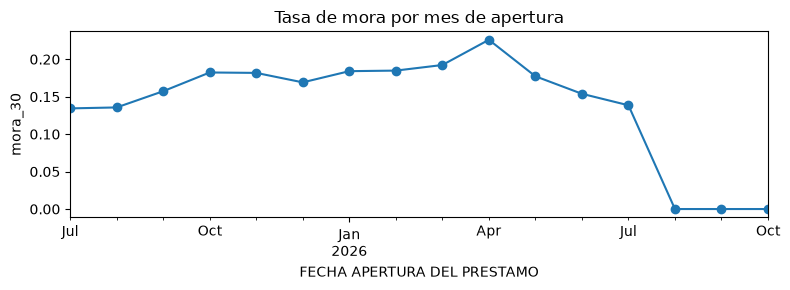

In [8]:
corte = pd.to_datetime(df["FECHA EFEC ULTIMO PAGO"].astype(str), format="%Y%m%d", errors="coerce").max()
print("fecha de corte (último pago registrado):", corte.date())
mes = apertura.dt.to_period("M")
tabla = fuera.groupby(mes[~bloque]).agg(creditos=("mora_30", "size"), mora=("mora_30", "mean"))
reciente = tabla.loc["2025-07":]
print(reciente.round(3).to_string())
ax = reciente["mora"].plot(marker="o", figsize=(8, 3), title="Tasa de mora por mes de apertura")
ax.set_ylabel("mora_30"); ax.axvline(reciente.index.get_loc(pd.Period("2026-06", "M")), color="gray", ls="--")
plt.tight_layout(); plt.savefig(FIG / "02_mora_por_mes_apertura.png", dpi=120); plt.show()

Los abiertos en agosto–octubre de 2026 tienen **0 %** de mora y julio solo 13,9 %: no ha pasado el tiempo. Se exige
que el crédito tenga **al menos 4 meses** al corte (apertura ≤ 30-jun-2026).

## 6. Variables conocidas al aprobar: ¿cuánta señal tienen?

In [9]:
base = fuera[apertura[~bloque] <= corte - pd.DateOffset(months=4)].copy()
print(f"base limpia: {len(base):,} créditos · mora {base['mora_30'].mean():.1%}")
candidatas = {"PLAZO UNIDAD TIEMPO PRODUCTO": "plazo", "VALOR ORIGINAL DEL PRESTAMO": "monto", "VLR CUOTA MES": "cuota",
              "VALOR EQUI. EFECTIVA VENCIDA": "tasa EA", "EDAD DEL CLIENTE": "edad", "DIA VENCIMIENTO CUOTA": "día de pago",
              "VALOR DE LA GARANTIA": "garantía"}
filas = {}
for col, nombre in candidatas.items():
    q = pd.qcut(base[col].rank(method="first"), 5, labels=False)
    filas[nombre] = base.groupby(q)["mora_30"].mean().round(3).tolist() + [round(auc_simple(base[col], base["mora_30"]), 3)]
print(pd.DataFrame(filas, index=["Q1", "Q2", "Q3", "Q4", "Q5", "AUC sola"]).T.to_string())
for c in ["NUMERO DEL PRODUCTO", "SEXO", "ESTADO CIVIL", "GARANTIA S/N"]:
    print(c, base.groupby(c)["mora_30"].mean().round(3).to_dict())
print("codeudor:", base.groupby(base["has_cosigner"])["mora_30"].mean().round(3).to_dict())
emp = base.groupby("NRO DEL CANAL DEL PRESTAMO")["mora_30"].agg(["size", "mean"])
print(f"empresas pagadoras: {len(emp)} · créditos por empresa (mediana): {emp['size'].median():.0f}")
grandes = emp[emp["size"] >= 50]
ruido = np.sqrt(base["mora_30"].mean() * (1 - base["mora_30"].mean()) / grandes["size"]).mean()
print(f"mora por empresa (≥ 50 créditos): desviación {grandes['mean'].std():.3f} vs ruido esperado por azar {ruido:.3f}")

base limpia: 46,050 créditos · mora 15.9%


                Q1     Q2     Q3     Q4     Q5  AUC sola
plazo        0.192  0.158  0.155  0.142  0.148     0.534
monto        0.164  0.166  0.163  0.158  0.144     0.517
cuota        0.162  0.157  0.160  0.159  0.159     0.503
tasa EA      0.153  0.160  0.168  0.162  0.152     0.501
edad         0.161  0.158  0.158  0.159  0.160     0.500
día de pago  0.159  0.158  0.156  0.163  0.159     0.501
garantía     0.165  0.160  0.162  0.163  0.146     0.510
NUMERO DEL PRODUCTO {117: 0.171, 118: 0.171, 120: 0.148, 121: 0.174, 128: 0.182, 200: 0.142, 410: 0.151}
SEXO {1: 0.158, 2: 0.161}
ESTADO CIVIL {1: 0.163, 2: 0.156, 7: 0.155}
GARANTIA S/N {'N': 0.162, 'S': 0.142}
codeudor: {0: 0.16, 1: 0.145}
empresas pagadoras: 421 · créditos por empresa (mediana): 32
mora por empresa (≥ 50 créditos): desviación 0.036 vs ruido esperado por azar 0.035


**Hallazgo central:** con lo que se sabe al aprobar, la señal es **débil**. Solo el plazo (más corto, más mora) tiene
una relación clara (AUC 0,53). Edad, sexo, estado civil, día de pago y ciudad apenas cambian la tasa, y las diferencias
entre empresas pagadoras no superan lo que daría el azar. Lo anotamos para que nadie espere un modelo milagroso:
el torneo dirá si un modelo supera una regla simple basada en el plazo.

## 7. Decisiones

In [10]:
decisiones = pd.DataFrame([
    ("49 columnas con datos personales (nombres, documentos, direcciones, teléfonos, codeudores)",
     "Eliminarlas al cargar; el cliente pasa a un seudónimo (hash) solo para agrupar", "Ley 1581; el modelo no las necesita"),
    (f"{len(vacias) + len(constantes)} columnas vacías o con un único valor", "Eliminarlas", "No pueden informar nada"),
    ("DIAS DE MORA sin vacíos ni negativos; 19,0 % > 30 días", "Objetivo mora_30 = DIAS DE MORA > 30", "Definición de la ficha"),
    ("Créditos abiertos ago–oct 2026 con 0 % de mora", "Exigir ≥ 4 meses de vida al corte (−10.331 créditos)", "Sin exposición, 'nuevo' parecería 'buen pagador'"),
    ("Bloque de 3.619 créditos con plazo = 1, tasa 950 y 100 % de mora", "Excluirlo", "Sus condiciones se reescribieron después de la mora (fuga)"),
    ("Saldos, pagos, intereses, estado y calificación con AUC 0,7–1,0", "Usar solo 13 columnas conocidas al aprobar", "Todo lo posterior a la aprobación es fuga"),
    ("12.627 clientes con más de un crédito", "Partir y validar por cliente; crear prior_credits (créditos anteriores)", "Evitar fuga entre particiones; el historial sí se conoce al aprobar"),
    ("Sexo y estado civil: 18,8 %–19,2 % de mora", "No usarlos como variables", "Atributos sensibles sin señal"),
    ("Afiliación del canal y utilizaciones: sin señal fuera del bloque", "No usarlas", "Señal aparente venía de la fuga; estado actual, no del día de aprobación"),
], columns=["Hallazgo", "Decisión", "Motivo"])
decisiones.index += 1
decisiones.to_csv(ROOT / "reports" / "02_decisiones_eda.csv")
decisiones

,Hallazgo,Decisión,Motivo
1,"49 columnas con datos personales (nombres, doc...",Eliminarlas al cargar; el cliente pasa a un se...,Ley 1581; el modelo no las necesita
2,63 columnas vacías o con un único valor,Eliminarlas,No pueden informar nada
3,"DIAS DE MORA sin vacíos ni negativos; 19,0 % >...",Objetivo mora_30 = DIAS DE MORA > 30,Definición de la ficha
4,Créditos abiertos ago–oct 2026 con 0 % de mora,Exigir ≥ 4 meses de vida al corte (−10.331 cré...,"Sin exposición, 'nuevo' parecería 'buen pagador'"
5,"Bloque de 3.619 créditos con plazo = 1, tasa 9...",Excluirlo,Sus condiciones se reescribieron después de la...
6,"Saldos, pagos, intereses, estado y calificació...",Usar solo 13 columnas conocidas al aprobar,Todo lo posterior a la aprobación es fuga
7,12.627 clientes con más de un crédito,Partir y validar por cliente; crear prior_cred...,Evitar fuga entre particiones; el historial sí...
8,"Sexo y estado civil: 18,8 %–19,2 % de mora",No usarlos como variables,Atributos sensibles sin señal
9,Afiliación del canal y utilizaciones: sin seña...,No usarlas,Señal aparente venía de la fuga; estado actual...
